# Tuning SVM RBF dengan Feature Engineering

Eksperimen `svm_rbf_tuning_fe` — Akram, Kelompok 17 DerbyCounty.
Screening parameter pada 3.000 baris stratified, lalu validasi OOF seluruh train
bersih dengan **training subsample 3.000 baris per fold**, dan perbandingan scikit-learn.


## Ringkasan hasil

- Parameter terpilih: `{'C': 1.0, 'gamma': 'scale'}`.
- **Training subsample 3.000 baris per fold**, validasi OOF seluruh **27.309 baris**.
- OOF from scratch **0.7612**, std **0.0056**, threshold **0.33**.
  Pembanding sklearn **0.7624** pada subsample train yang sama.
- Model utama konvergen **5/5 fold**; peringatan training/kalibrasi **0**.
  Waktu CV from scratch 123.6 detik; sklearn 28.8 detik.

Skor ini menggunakan training subsample; jumlah data latihnya berbeda dari baseline linear full-training.


## Metode

Grid dan screening 3.000 baris tetap mengikuti eksperimen awal. Untuk evaluasi
lanjutan, setiap train fold disampling stratified menjadi 3.000 baris dengan seed
42. Kelima validation fold tetap mencakup seluruh 27.309 baris train bersih, sama
dengan baseline tim. Preprocessor hanya di-fit pada subsample train fold itu.
From scratch dan scikit-learn menggunakan indeks training dan validasi yang sama.

Training from scratch pada evaluasi lanjutan dibatasi 200 iterasi, tol 0.01.
Status konvergensi dan peringatan tetap dilaporkan. Skor ini harus diberi label
training subsample; jumlah data latihnya berbeda dari baseline full-training.
Screening dan threshold menggunakan data pengembangan, bukan test independen.
Run full-training sebelumnya dihentikan karena terlalu lama. Data test tidak dipakai.


In [1]:
import hashlib
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'models').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from models import SVM
from preprocessing import SVMPreprocessor, TARGET, clean_train
from utils import (best_threshold, confusion_matrix, cross_val_proba,
                   f1_per_class, fold_scores, macro_f1, stratified_kfold)

SEED = 42
N_FOLDS = 5
SCREEN_SIZE = 3000
KERNEL = 'rbf'
EXP_NAME = 'svm_rbf_tuning_fe'
BASE_PARAMS = dict(kernel=KERNEL, tol=0.01, max_iter=1000, seed=SEED)
GRID = [{'C': 1.0, 'gamma': 'scale'}, {'C': 1.0, 'gamma': 0.1}, {'C': 10.0, 'gamma': 'scale'}, {'C': 10.0, 'gamma': 0.1}]
FIG_PATH = ROOT / 'output' / 'figures' / f'{EXP_NAME}.png'
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Python', sys.version.split()[0], '| NumPy', np.__version__,
      '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)
print('Grid:', GRID)

Python 3.12.6 | NumPy 2.2.6 | pandas 2.3.0 | scikit-learn 1.9.0
Grid: [{'C': 1.0, 'gamma': 'scale'}, {'C': 1.0, 'gamma': 0.1}, {'C': 10.0, 'gamma': 'scale'}, {'C': 10.0, 'gamma': 0.1}]


## Data dan pemeriksaan fold

Semua baris memiliki tepat satu prediksi validasi di masing-masing skema.
Sampel screening hanya mengambil data train; data test tidak dipakai.

In [2]:
train_raw = pd.read_csv(ROOT / 'data' / 'train.csv', dtype={'id': str})
train = clean_train(train_raw)
y = train[TARGET].to_numpy()
folds = stratified_kfold(y, n_splits=N_FOLDS, seed=SEED)
screen_train = train.groupby(TARGET, group_keys=False).sample(
    frac=SCREEN_SIZE / len(train), random_state=SEED).reset_index(drop=True)
screen_y = screen_train[TARGET].to_numpy()
screen_folds = stratified_kfold(screen_y, n_splits=N_FOLDS, seed=SEED)
for labels, splits in [(y, folds), (screen_y, screen_folds)]:
    assert set(np.unique(labels)) == {0, 1}
    assert np.array_equal(np.sort(np.concatenate([va for _, va in splits])),
                          np.arange(len(labels)))
    assert all(not np.intersect1d(tr, va).size and len(tr) + len(va) == len(labels)
               for tr, va in splits)
print('Train mentah:', len(train_raw), '| Train bersih:', len(train),
      '| Screening:', len(screen_train))
print('SHA256 train.csv:', hashlib.sha256((ROOT / 'data' / 'train.csv').read_bytes()).hexdigest())
display(pd.DataFrame({'penuh': train[TARGET].value_counts(),
                      'screening': screen_train[TARGET].value_counts()}).sort_index())

def report(name, labels, proba, splits, seconds):
    assert proba.shape == labels.shape and np.isfinite(proba).all()
    assert ((0 <= proba) & (proba <= 1)).all()
    threshold, score = best_threshold(labels, proba)
    scores = fold_scores(labels, proba, splits, threshold)
    assert np.isclose(score, f1_score(labels, proba >= threshold, average='macro'))
    return dict(model=name, threshold=threshold, oof_macro_f1=score,
                fold_mean=float(scores.mean()), fold_std=float(scores.std()),
                cv_seconds=seconds)

Train mentah: 27373 | Train bersih: 27309 | Screening: 3000
SHA256 train.csv: 2773be159fee45aac59b32354949d00af0badbc37c45420d5ab5dc676bbcc7ed


,penuh,screening
is_canceled,,
0,18365,2017
1,8944,983


## Screening parameter

Setiap konfigurasi memakai model from scratch dan preprocessor baru per fold.
Peringatan dicatat termasuk model sementara untuk kalibrasi probabilitas.
Training dibatasi satu thread BLAS per proses.

In [3]:
screening_rows = []
for candidate, params in enumerate(GRID, 1):
    print(f'Screening {candidate}/{len(GRID)}: {params}', flush=True)
    models = []

    def make_candidate():
        model = SVM(**BASE_PARAMS, **params)
        models.append(model)
        return model

    started = time.perf_counter()
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as messages:
        warnings.simplefilter('always', RuntimeWarning)
        proba = cross_val_proba(make_candidate, SVMPreprocessor,
                               screen_train, screen_y, screen_folds)
    row = report('SVM from scratch', screen_y, proba, screen_folds,
                 time.perf_counter() - started)
    row.update(candidate=candidate, params=params,
               converged_folds=sum(model.converged_ for model in models),
               warning_count=len(messages))
    screening_rows.append(row)
    print(f"  OOF sampel={row['oof_macro_f1']:.4f}, konvergen={row['converged_folds']}/5, "
          f"peringatan={row['warning_count']}, waktu={row['cv_seconds']:.1f}s", flush=True)

screening = pd.DataFrame(screening_rows)
display(screening.drop(columns='model').round(4))
eligible = screening[(screening['converged_folds'] == N_FOLDS)
                     & (screening['warning_count'] == 0)]
assert not eligible.empty, 'Tidak ada kandidat screening yang konvergen tanpa peringatan.'
best_params = dict(eligible.sort_values('oof_macro_f1', ascending=False,
                                       kind='stable').iloc[0]['params'])
print('Parameter terpilih:', best_params)

Screening 1/4: {'C': 1.0, 'gamma': 'scale'}


  OOF sampel=0.7616, konvergen=5/5, peringatan=0, waktu=39.9s


Screening 2/4: {'C': 1.0, 'gamma': 0.1}


  OOF sampel=0.7269, konvergen=5/5, peringatan=0, waktu=66.6s


Screening 3/4: {'C': 10.0, 'gamma': 'scale'}


  OOF sampel=0.7568, konvergen=5/5, peringatan=0, waktu=113.2s


Screening 4/4: {'C': 10.0, 'gamma': 0.1}


  OOF sampel=0.7175, konvergen=5/5, peringatan=0, waktu=96.9s


,threshold,oof_macro_f1,fold_mean,fold_std,cv_seconds,candidate,params,converged_folds,warning_count
0,0.35,0.7616,0.7615,0.0127,39.9312,1,"{'C': 1.0, 'gamma': 'scale'}",5,0
1,0.29,0.7269,0.7267,0.0088,66.5569,2,"{'C': 1.0, 'gamma': 0.1}",5,0
2,0.36,0.7568,0.7567,0.0111,113.2279,3,"{'C': 10.0, 'gamma': 'scale'}",5,0
3,0.37,0.7175,0.7172,0.0154,96.8764,4,"{'C': 10.0, 'gamma': 0.1}",5,0


Parameter terpilih: {'C': 1.0, 'gamma': 'scale'}


## OOF seluruh data dengan training subsample

Setiap train fold memakai 3.000 baris stratified. Validation fold tetap utuh.
Preprocessing, training, dan kalibrasi hanya memakai subsample train tersebut.


In [4]:
TRAIN_SIZE = 3000
EVAL_PARAMS = dict(BASE_PARAMS, max_iter=200)
rng = np.random.default_rng(SEED)
eval_folds = []
for tr, va in folds:
    chosen = []
    for label in np.unique(y):
        candidates = tr[y[tr] == label]
        size = round(TRAIN_SIZE * len(candidates) / len(tr))
        chosen.extend(rng.choice(candidates, size=size, replace=False))
    chosen = np.sort(chosen)
    assert len(chosen) == TRAIN_SIZE and len(np.unique(chosen)) == TRAIN_SIZE
    assert np.isin(chosen, tr).all() and not np.intersect1d(chosen, va).size
    assert set(np.unique(y[chosen])) == {0, 1}
    eval_folds.append((chosen, va))
assert np.array_equal(np.sort(np.concatenate([va for _, va in eval_folds])), np.arange(len(y)))
print('Training per fold:', TRAIN_SIZE, '| Validasi total:', len(y), '| max_iter:', EVAL_PARAMS['max_iter'])

scratch_models = []

def make_scratch():
    print(f'Mulai fold subsample {len(scratch_models) + 1}/{N_FOLDS}', flush=True)
    model = SVM(**EVAL_PARAMS, **best_params)
    scratch_models.append(model)
    return model

started = time.perf_counter()
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as cv_warnings:
    warnings.simplefilter('always', RuntimeWarning)
    oof_scratch = cross_val_proba(make_scratch, SVMPreprocessor, train, y, eval_folds)
res_scratch = report('SVM from scratch', y, oof_scratch, eval_folds,
                     time.perf_counter() - started)
diagnostics = pd.DataFrame([
    dict(fold=k, iterations=model.n_iter_, converged=model.converged_,
         support_vectors=len(model.support_))
    for k, model in enumerate(scratch_models, 1)
])
display(pd.DataFrame([res_scratch]).set_index('model').round(4))
display(diagnostics)
print('Peringatan CV subsample termasuk kalibrasi:', len(cv_warnings))
for message in sorted({str(w.message) for w in cv_warnings}):
    print(message)

Training per fold:

 3000 | Validasi total: 27309 | max_iter: 200


Mulai fold subsample 1/5


Mulai fold subsample 2/5


Mulai fold subsample 3/5


Mulai fold subsample 4/5


Mulai fold subsample 5/5


,threshold,oof_macro_f1,fold_mean,fold_std,cv_seconds
model,,,,,
SVM from scratch,0.33,0.7612,0.7611,0.0056,123.609


,fold,iterations,converged,support_vectors
0,1,21,True,1729
1,2,18,True,1617
2,3,17,True,1715
3,4,17,True,1727
4,5,24,True,1692


Peringatan CV subsample termasuk kalibrasi: 0


## Perbandingan scikit-learn

SVC memakai kernel, C, gamma, degree, coef0, toleransi, preprocessing,
dan fold luar yang sama. Solver SVC tidak dibatasi jumlah iterasi.
`CalibratedClassifierCV` memakai sigmoid dan 5-fold internal dengan seed 42,
`ensemble=False`, sehingga prediksi berasal dari satu SVC yang dilatih
pada seluruh train fold luar. From scratch memakai holdout internal 20%;
probabilitas kedua metode tidak harus sama.

SVC juga hanya dilatih pada subsample train yang sama (3.000 baris per fold).

In [5]:
class SklearnWrapper:
    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

reference_models = []

def make_reference():
    print(f'Mulai fold sklearn {len(reference_models) + 1}/{N_FOLDS}', flush=True)
    model = SklearnWrapper(CalibratedClassifierCV(
        SVC(kernel=KERNEL, **best_params, tol=BASE_PARAMS['tol'], random_state=SEED),
        method='sigmoid', ensemble=False,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)))
    reference_models.append(model)
    return model

started = time.perf_counter()
with threadpool_limits(limits=1):
    oof_sklearn = cross_val_proba(make_reference, SVMPreprocessor, train, y, eval_folds)
res_sklearn = report('sklearn SVC', y, oof_sklearn, folds,
                     time.perf_counter() - started)
comparison = pd.DataFrame([res_scratch, res_sklearn]).set_index('model')
display(comparison.round(4))
per_fold = pd.DataFrame({
    'fold': np.arange(1, N_FOLDS + 1),
    'from_scratch': fold_scores(y, oof_scratch, folds, res_scratch['threshold']),
    'sklearn': fold_scores(y, oof_sklearn, folds, res_sklearn['threshold']),
})
display(per_fold.round(4))
pred_oof = (oof_scratch >= res_scratch['threshold']).astype(int)
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(confusion_matrix(y, pred_oof))
print('F1 kelas 0 dan 1:', f1_per_class(y, pred_oof).round(4))
print('Selisih OOF from scratch - sklearn:',
      round(res_scratch['oof_macro_f1'] - res_sklearn['oof_macro_f1'], 6))

Mulai fold sklearn 1/5


Mulai fold sklearn 2/5


Mulai fold sklearn 3/5


Mulai fold sklearn 4/5


Mulai fold sklearn 5/5


,threshold,oof_macro_f1,fold_mean,fold_std,cv_seconds
model,,,,,
SVM from scratch,0.33,0.7612,0.7611,0.0056,123.6090
sklearn SVC,0.35,0.7624,0.7623,0.0053,28.8291


,fold,from_scratch,sklearn
0,1,0.7565,0.7587
1,2,0.7714,0.7716
2,3,0.7623,0.7649
3,4,0.7565,0.7583
4,5,0.7588,0.7583


Confusion matrix [[TN, FP], [FN, TP]]:
[[14969  3396]
 [ 2492  6452]]
F1 kelas 0 dan 1: [0.8357 0.6867]
Selisih OOF from scratch - sklearn: -0.001199


## Diagnostik OOF training subsample

Validation fold tetap utuh; model hanya dilatih pada 3.000 baris per fold.
Std menunjukkan penyebaran skor lima fold (ddof=0), bukan confidence interval.


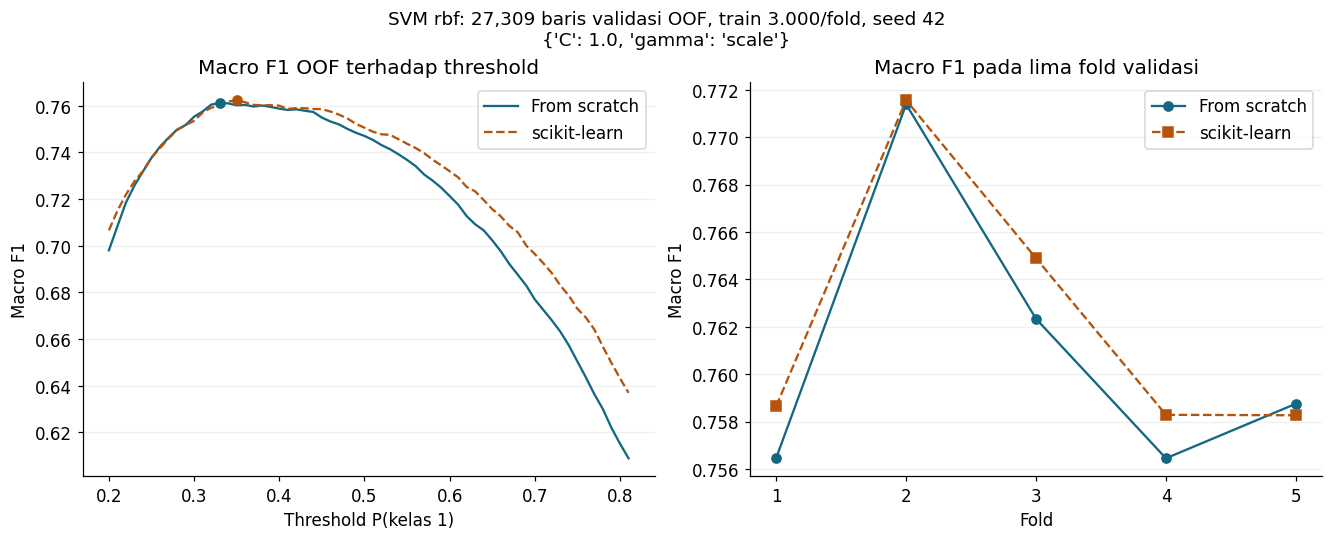

In [6]:
thresholds = np.round(np.arange(0.20, 0.81, 0.01), 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for name, proba, result, color, style in [
    ('From scratch', oof_scratch, res_scratch, '#126782', '-'),
    ('scikit-learn', oof_sklearn, res_sklearn, '#b45309', '--'),
]:
    axes[0].plot(thresholds, [macro_f1(y, proba >= t) for t in thresholds],
                 label=name, color=color, linestyle=style)
    axes[0].scatter(result['threshold'], result['oof_macro_f1'], color=color, zorder=3)
axes[0].set(title='Macro F1 OOF terhadap threshold', xlabel='Threshold P(kelas 1)',
            ylabel='Macro F1')
axes[0].legend()
axes[1].plot(per_fold['fold'], per_fold['from_scratch'], 'o-',
             color='#126782', label='From scratch')
axes[1].plot(per_fold['fold'], per_fold['sklearn'], 's--',
             color='#b45309', label='scikit-learn')
axes[1].set(title='Macro F1 pada lima fold validasi', xlabel='Fold', ylabel='Macro F1',
            xticks=range(1, N_FOLDS + 1))
axes[1].legend()
for ax in axes:
    ax.grid(axis='y', alpha=0.2)
fig.suptitle(f'SVM {KERNEL}: {len(y):,} baris validasi OOF, train 3.000/fold, seed {SEED}\n{best_params}',
             fontsize=12)
FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_PATH, dpi=150)
plt.show()

## Catatan hasil

Skor mencakup seluruh validation fold, dengan training subsample 3.000 baris per
fold. Perbandingan from scratch/sklearn memakai baris yang sama. Hasil ini belum
mengukur performa model yang dilatih pada seluruh train fold. Tidak ada submission Kaggle.


Hasil from scratch 0.7612 dan sklearn 0.7624 berlaku untuk
protokol training subsample ini. Keduanya memakai indeks train/validasi yang sama,
namun metode kalibrasi probabilitas berbeda. Grid kecil dan pemilihan threshold
ini adalah pengembangan model, bukan estimasi test independen.

Reproduksi dari root repo, dengan batas 10 menit per sel:

```bash
python -m jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=600 src/experiments/svm/svm_rbf_tuning_fe.ipynb
```
